# 06 · Decision Framework

**The honest guide.** This notebook synthesizes the whole project. It reads back the JSON artifacts the earlier notebooks saved to `outputs/data/`, assembles the summary figure, and writes the final verdict — what is real today, what is hype, what you can simulate, and why not to expect a quick win by scaling.

The rule that organizes everything: **always run the classical baseline.** QML's job is to beat it, and on the problems you can actually run, it usually does not yet.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## Read back what we measured

Every claim below is loaded from a JSON file an earlier notebook produced — the numbers are measured, not asserted.

In [2]:
def load(name):
    return json.loads((DATA / name).read_text())

validation = load('01_validation.json')
scaling = load('02_scaling.json')
landmarks = load('02_scaling_landmarks.json')['landmarks']
arena03 = load('03_arena.json')
planted = load('03_planted_spotlight.json')
barren = load('05_variances_vs_qubits.json')

print('simulator vs PennyLane, worst case:', max(validation.values()))
print('memory at 20/26 qubits:', landmarks['20']['human'], '/', landmarks['26']['human'])
print('barren decay per qubit:', round(barren['decay_per_qubit'], 3))

simulator vs PennyLane, worst case: 0.0
memory at 20/26 qubits: 16.8 MB / 1073.7 MB
barren decay per qubit: 0.521


## The whole story in one figure

Four panels: the $2^N$ simulation wall, the barren plateau, the arena (best classical vs best quantum per dataset), and the engineered exception.

saved outputs/figures/06_summary.png


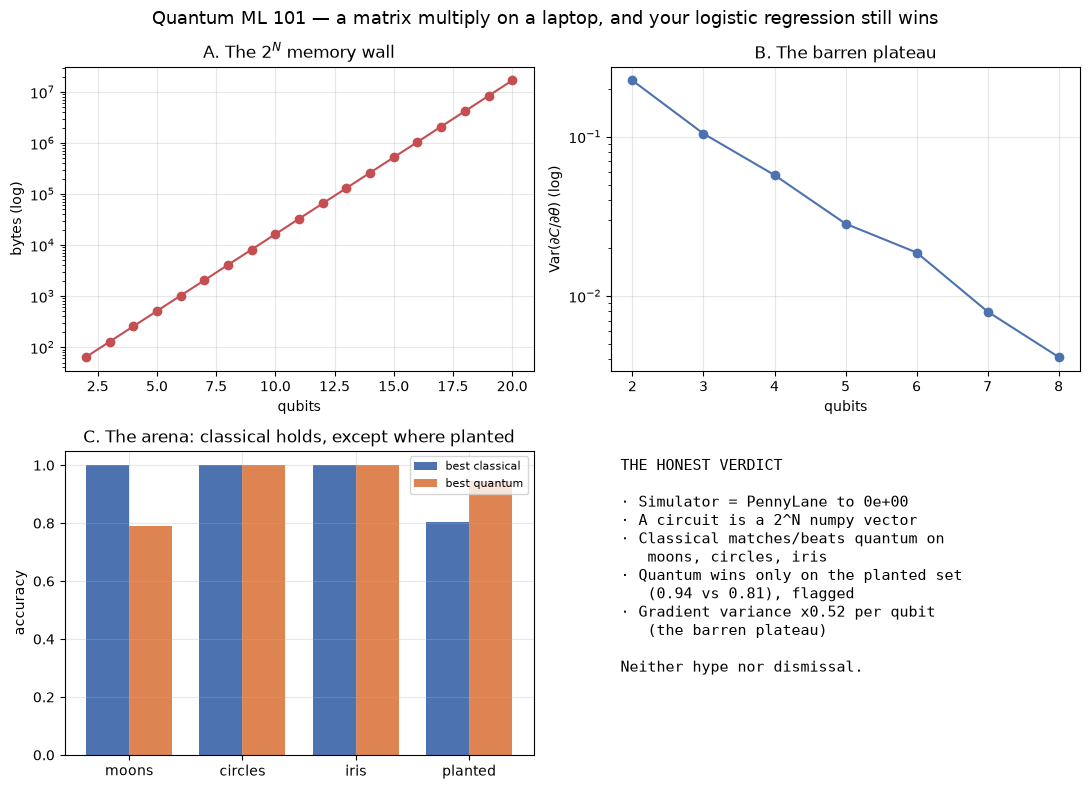

In [3]:
best = {}
for d, r in arena03.items():
    best[d] = {
        'classical': max(r['logistic'], r['rbf_svm']),
        'quantum': max(r['q_kernel_angle'], r['q_kernel_zz']),
    }

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# A: the 2^N wall
ax = axes[0, 0]
qs = [int(k) for k in scaling]
mem = [scaling[str(n)]['bytes'] for n in qs]
ax.semilogy(qs, mem, 'o-', color='#c44e52')
ax.set_title('A. The $2^N$ memory wall')
ax.set_xlabel('qubits'); ax.set_ylabel('bytes (log)')

# B: barren plateau
ax = axes[0, 1]
ax.semilogy(barren['qubits'], barren['variance'], 'o-', color='#4c72b0')
ax.set_title('B. The barren plateau')
ax.set_xlabel('qubits'); ax.set_ylabel(r'Var$(\partial C/\partial\theta)$ (log)')

# C: arena
ax = axes[1, 0]
names = list(best)
x = np.arange(len(names)); w = 0.38
ax.bar(x - w / 2, [best[d]['classical'] for d in names], w, label='best classical', color='#4c72b0')
ax.bar(x + w / 2, [best[d]['quantum'] for d in names], w, label='best quantum', color='#dd8452')
ax.set_xticks(x, names); ax.set_ylim(0, 1.05)
ax.set_title('C. The arena: classical holds, except where planted'); ax.set_ylabel('accuracy')
ax.legend(fontsize=8)

# D: verdict card
ax = axes[1, 1]; ax.axis('off')
verdict_text = (
    'THE HONEST VERDICT\n\n'
    f'· Simulator = PennyLane to {max(validation.values()):.0e}\n'
    '· A circuit is a 2^N numpy vector\n'
    f'· Classical matches/beats quantum on\n   moons, circles, iris\n'
    f'· Quantum wins only on the planted set\n   ({planted["quantum_zz_accuracy"]:.2f} vs {planted["best_classical_accuracy"]:.2f}), flagged\n'
    f'· Gradient variance x{barren["decay_per_qubit"]:.2f} per qubit\n   (the barren plateau)\n\n'
    'Neither hype nor dismissal.'
)
ax.text(0.02, 0.98, verdict_text, va='top', ha='left', fontsize=11, family='monospace')

fig.suptitle('Quantum ML 101 — a matrix multiply on a laptop, and your logistic regression still wins', fontsize=13)
fig.tight_layout()
save_fig(fig, '06_summary.png')

## What you can simulate, and the keyless software landscape

On this 2-CPU / 8 GB machine, demos run comfortably at **~16–18 qubits** and the hard statevector ceiling is around **26–28** before memory and copies dominate. Everything here used **free, keyless, local** software:

- **PennyLane + lightning** and **Qiskit + Aer** both run locally with no account.
- The from-scratch simulator needs only **numpy**.
- **Real-hardware access** (QPUs, queues, device noise) needs an account and is a separate world — deliberately out of scope here, and unnecessary for learning.

In [4]:
bytes_budget = 8 * 1024**3  # 8 GB
hard_ceiling = int(np.log2(bytes_budget / 16))
landscape = {
    'comfortable_demo_qubits': '16-18',
    'hard_statevector_ceiling_qubits': hard_ceiling,
    'keyless_local_libraries': ['pennylane + lightning', 'qiskit + aer', 'from-scratch numpy'],
    'needs_account': ['real quantum hardware (QPUs)'],
    'out_of_scope': 'QPUs, cloud queues, device noise',
}
print('one 8 GB statevector tops out near', hard_ceiling, 'qubits')
save_json('06_landscape.json', landscape)

one 8 GB statevector tops out near 29 qubits
saved outputs/data/06_landscape.json


## The final verdict (written to `outputs/data/06_verdict.json`)

In [5]:
verdict = {
    'thesis': 'A quantum circuit is a 2^N complex vector acted on by matrix-multiply '
              'gates; quantum-kernel SVMs and VQCs are matched or beaten by classical '
              'baselines on runnable data; the barren plateau is the measured reason '
              'deep VQCs do not train.',
    'real_today': [
        'the ideas and the math (small linear algebra)',
        'from-scratch simulation matching PennyLane to machine precision',
        'quantum kernels as legitimate PSD kernels',
        'small-scale behavior of VQCs trained by gradient descent',
    ],
    'hype': [
        'beating classical models on ordinary data at runnable scale',
        'scaling a random deep VQC to force an advantage',
    ],
    'measured': {
        'simulator_vs_pennylane_worst_case': max(validation.values()),
        'memory_20q': landmarks['20']['human'],
        'memory_26q': landmarks['26']['human'],
        'arena_best_classical_vs_quantum': best,
        'planted_exception': planted,
        'barren_decay_per_qubit': barren['decay_per_qubit'],
        'barren_collapse_factor': barren['collapse_factor'],
    },
    'rule': 'Always run the classical baseline.',
}
save_json('06_verdict.json', verdict)
print(json.dumps({'real_today': verdict['real_today'], 'hype': verdict['hype']}, indent=2))

saved outputs/data/06_verdict.json
{
  "real_today": [
    "the ideas and the math (small linear algebra)",
    "from-scratch simulation matching PennyLane to machine precision",
    "quantum kernels as legitimate PSD kernels",
    "small-scale behavior of VQCs trained by gradient descent"
  ],
  "hype": [
    "beating classical models on ordinary data at runnable scale",
    "scaling a random deep VQC to force an advantage"
  ]
}


## Ships with

The from-scratch simulator, the quantum kernel and VQC, the classical baselines, and the barren-plateau and scaling analyses — working code and a sound mental model. The honest verdict is neither hype nor dismissal: the ideas of QML are real and small enough to hold in your hand and simulate on two CPUs for free, but today, on the problems you can actually run, **classical wins**, and the barren plateau is the measured reason deep quantum models do not simply train their way past it.